# What limits HOM visibility? Polarization vs. spectral mismatch

A Hong–Ou–Mandel (HOM) dip with only ~64% visibility leaves you asking *which* imperfection ate the
missing contrast. This notebook covers two common causes for **signal–idler HOM interference from a
type-II ppKTP source** (e.g. one arm of a Sagnac entangled-photon source, with the idler polarization
rotated by 90° before the beam splitter):

1. **Polarization mismatch.** After the 90° rotation the two photons don't have exactly the same polarization.
2. **Spectral mismatch.** The signal and idler spectra don't overlap, e.g. because the crystal temperature
   is off the degenerate point.

It covers:

- **Part 1:** the math behind `HOMAnalyzer.compute_two_mode_HOM`, now with a polarization overlap
  $|\langle p_1|p_2\rangle|^2$ (`pol1`/`pol2` arguments).
- **Part 2:** polarization only, with linear offsets and elliptical states.
- **Part 3:** spectral mismatch. This section also shows that, for photons from the **same pair**, the
  density-matrix formula is *not* the right model. It is replaced by the JSA exchange overlap.
- **Part 4:** both effects combined, plus a fit template you can point at experimental data.

## Part 1: The math

### Two independent photons

Photon 1 enters beam-splitter port $a$ in the (mixed) spectral state $\rho_1$ and polarization $|p_1\rangle$.
Photon 2 enters port $b$ in $\rho_2$, $|p_2\rangle$. If the two photons are **uncorrelated**, the input
state is a product,

$$
\varrho_\text{in} = \big(\rho_1 \otimes |p_1\rangle\langle p_1|\big)_a \otimes \big(\rho_2 \otimes |p_2\rangle\langle p_2|\big)_b .
$$

A lossless beam splitter with reflectivity $R$ and transmissivity $T = 1 - R$ maps
$a^\dagger \to \sqrt{T}\,c^\dagger + \sqrt{R}\,d^\dagger$ and $b^\dagger \to \sqrt{R}\,c^\dagger - \sqrt{T}\,d^\dagger$.
There are two ways to get one photon in each output: both transmitted (amplitude $\propto T$) or both
reflected (amplitude $\propto -R$). For pure states, the probability of a coincidence is

$$
P_c = T^2 + R^2 - 2RT\,\big|\langle \psi_1 | \psi_2 \rangle\big|^2 .
$$

The two paths interfere only as far as the photons are **indistinguishable in every degree of
freedom**. For mixed states, $|\langle\psi_1|\psi_2\rangle|^2 \to \mathrm{Tr}[\varrho_1\varrho_2]$. The
spectral and polarization parts are a tensor product, so the trace factorizes:

$$
\boxed{\;P_c(\tau) = R^2 + T^2 - 2RT\;\underbrace{|\langle p_1|p_2\rangle|^2}_{\text{polarization}}\;
\underbrace{\mathrm{Re}\,\mathrm{Tr}\!\big[\rho_1\,\rho_2(\tau)\big]}_{\text{spectral}}\;}
$$

This is the formula behind `compute_two_mode_HOM`. The `pol1`/`pol2` arguments supply the polarization
factor, which defaults to 1 (identical polarizations).

### Delay

Delaying photon 2 by $\tau$ multiplies each frequency component by a phase. In the frequency-bin basis
the density matrix becomes

$$
\rho_2(f, f'; \tau) = e^{-i 2\pi (f - f')\tau}\,\rho_2(f, f') ,
$$

which is `hom_math.apply_delay_to_rho_freq`. At large $|\tau|$ the phases average out,
$\mathrm{Tr}[\rho_1\rho_2(\tau)] \to 0$, and $P_c \to R^2 + T^2$, the classical baseline.

### Why a "relative phase" alone does nothing

A frequency-independent phase on photon 2, $|\psi_2\rangle \to e^{i\varphi}|\psi_2\rangle$, gives
$\rho_2 \to e^{i\varphi}\rho_2 e^{-i\varphi} = \rho_2$. The dip doesn't change. A phase only matters if it
(a) depends on frequency (dispersion, as in the delay operator above), or (b) sits *between the H and V
components* of the polarization. Case (b) makes the polarization elliptical, and its whole effect enters
through $|\langle p_1|p_2\rangle|^2$.

### Polarization overlap

For Jones vectors $p = (p_H, p_V)$,

$$
|\langle p_1|p_2\rangle|^2 = \frac{|p_{1H}^* p_{2H} + p_{1V}^* p_{2V}|^2}{\|p_1\|^2\|p_2\|^2}.
$$

- Linear polarizations at relative angle $\theta$: $|\langle p_1|p_2\rangle|^2 = \cos^2\theta$.
- Diagonal $|D\rangle = (1,1)/\sqrt{2}$ against $(1, e^{i\phi})/\sqrt{2}$ (a birefringent phase $\phi$
  in one arm, e.g. from a fiber): $|\langle p_1|p_2\rangle|^2 = (1+\cos\phi)/2$.

### Visibility

With $V \equiv (P_c^\text{max} - P_c^\text{min})/P_c^\text{max}$ and the dip at $\tau = 0$:

$$
V = \frac{2RT}{R^2+T^2}\;|\langle p_1|p_2\rangle|^2\;\mathrm{Tr}[\rho_1\rho_2].
$$

The three factors (beam-splitter balance, polarization, spectrum) multiply.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import RegularGridInterpolator
from scipy.optimize import curve_fit

from photonpairlab import (
    Crystal,
    HOMAnalyzer,
    MaterialFactory,
    PulsedLaser,
    SPDC_Simulation,
    SPDCGridConfig,
)
from photonpairlab.spdc.analysis import linear_polarization, polarization_overlap

warnings.filterwarnings("ignore")

## Setup

KTP, type-II, 30 mm, periodic poling designed for degenerate 1550 nm at 25 °C, pumped by a 1.7 ps
pulsed laser at 775 nm. The same source as in `demo.ipynb`.

`compute_two_mode_HOM` requires both photons on the **same wavelength grid**. To interfere signal with
idler, we therefore use identical explicit ranges, `signal_range == idler_range`.

In [2]:
material = MaterialFactory.create("ktp1")
laser = PulsedLaser(775e-9, pulse_duration=1.7e-12)
crystal_length = 30e-3
wl0 = 1550e-9
T_design = 25.0

wl_range = (1544e-9, 1556e-9)
grid = SPDCGridConfig(steps=100, signal_range=wl_range, idler_range=wl_range)

H = linear_polarization(0.0)


def simulate(T=T_design):
    # Pole for degeneracy at T_design, then operate the crystal at temperature T.
    design = Crystal(crystal_length=crystal_length, material=material, pm_strategy="quasi",
                     spdc_type="type-II", T=T_design)
    poling = design.generate_poling(laser=laser, mode="periodic",
                                    wavelength_signal=wl0, wavelength_idler=wl0, resolution=5)
    crystal = Crystal(crystal_length=crystal_length, material=material, pm_strategy="quasi",
                      spdc_type="type-II", T=T, coherence_length=design.coherence_length)
    crystal.apply_poling(poling)
    sim = SPDC_Simulation(crystal, laser, wavelength_signal=wl0, wavelength_idler=wl0, grid=grid)
    return sim.run()


def visibility(Pc, R=0.5, T=0.5):
    baseline = R**2 + T**2
    return (baseline - Pc.min()) / baseline


results = simulate()
taus = np.linspace(-6e-12, 6e-12, 601)
taus_ps = taus * 1e12

## Part 2: Polarization only

We interfere the signal with the idler of the *same* simulation (spectrally degenerate), and rotate photon
2 by $\theta$ away from photon 1. The polarization factor multiplies the whole dip, so the **shape is
unchanged and only the depth scales**, as $\cos^2\theta$.

(The absolute $V_0$ printed here comes from the density-matrix model. Part 3 shows that for signal and
idler of the *same* pair the correct value is ≈ 0.99. The $\cos^2\theta$ scaling is identical in both
models.)

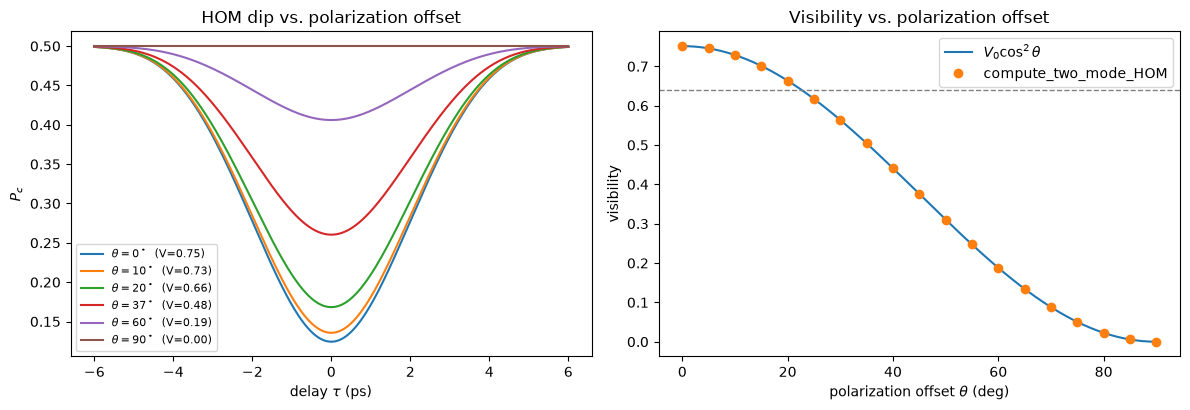

V0 (identical polarizations, density-matrix model) = 0.751
Polarization offset alone needed for 64% of V0: theta = 36.9 deg


In [3]:
hom = HOMAnalyzer(results, results)

fig, (ax_dip, ax_v) = plt.subplots(1, 2, figsize=(12, 4.2))
for deg in [0, 10, 20, 37, 60, 90]:
    res = hom.compute_two_mode_HOM("signal", "idler", taus_s=taus,
                                   pol1=H, pol2=linear_polarization(np.deg2rad(deg)))
    ax_dip.plot(taus_ps, res.coincidence_probabilities,
                label=fr"$\theta={deg}^\circ$  (V={visibility(res.coincidence_probabilities):.2f})")
ax_dip.set(xlabel=r"delay $\tau$ (ps)", ylabel=r"$P_c$", title="HOM dip vs. polarization offset")
ax_dip.legend(fontsize=8)

V0 = visibility(hom.compute_two_mode_HOM("signal", "idler", taus_s=taus).coincidence_probabilities)
thetas = np.linspace(0, 90, 19)
V_num = [visibility(hom.compute_two_mode_HOM("signal", "idler", taus_s=np.array([0.0]),
                                             pol1=H, pol2=linear_polarization(np.deg2rad(t))).coincidence_probabilities)
         for t in thetas]
th_fine = np.linspace(0, 90, 300)
ax_v.plot(th_fine, V0 * np.cos(np.deg2rad(th_fine))**2, label=r"$V_0\cos^2\theta$")
ax_v.plot(thetas, V_num, "o", label="compute_two_mode_HOM")
ax_v.axhline(0.64, color="gray", ls="--", lw=1)
ax_v.set(xlabel=r"polarization offset $\theta$ (deg)", ylabel="visibility",
         title="Visibility vs. polarization offset")
ax_v.legend()
plt.tight_layout()
plt.show()

print(f"V0 (identical polarizations, density-matrix model) = {V0:.3f}")
print(f"Polarization offset alone needed for 64% of V0: theta = {np.rad2deg(np.arccos(np.sqrt(0.64))):.1f} deg")

$\theta \approx 37^\circ$ is a large error for a half-wave plate. A misaligned plate alone is therefore
unlikely to explain 64%. A **birefringent phase** in a fiber (an elliptical state) is a more plausible
source of polarization distinguishability. With diagonal input, a phase $\phi$ between H and V gives
$(1+\cos\phi)/2$:

In [4]:
D = np.array([1, 1]) / np.sqrt(2)
for phi_deg in [0, 30, 60, 74, 90, 180]:
    p2 = np.array([1, np.exp(1j * np.deg2rad(phi_deg))]) / np.sqrt(2)
    print(f"phi = {phi_deg:3d} deg  ->  |<p1|p2>|^2 = {polarization_overlap(D, p2):.3f}"
          f"   (analytic {(1 + np.cos(np.deg2rad(phi_deg))) / 2:.3f})")

phi =   0 deg  ->  |<p1|p2>|^2 = 1.000   (analytic 1.000)
phi =  30 deg  ->  |<p1|p2>|^2 = 0.933   (analytic 0.933)
phi =  60 deg  ->  |<p1|p2>|^2 = 0.750   (analytic 0.750)
phi =  74 deg  ->  |<p1|p2>|^2 = 0.638   (analytic 0.638)
phi =  90 deg  ->  |<p1|p2>|^2 = 0.500   (analytic 0.500)
phi = 180 deg  ->  |<p1|p2>|^2 = 0.000   (analytic 0.000)


## Part 3: Spectral mismatch

### The density-matrix formula underestimates same-pair interference

The $\rho_1\rho_2$ formula assumes **uncorrelated** photons. Signal and idler from one SPDC event are
spectrally *correlated*. Their joint state is

$$
|\psi\rangle = \iint d\omega_s\, d\omega_i\; f(\omega_s,\omega_i)\, a^\dagger(\omega_s)\, b^\dagger(\omega_i)\, |0\rangle ,
$$

and the same beam-splitter calculation (now keeping the full JSA $f$) gives

$$
P_c(\tau) = R^2 + T^2 - 2RT\,|\langle p_1|p_2\rangle|^2\;
\mathrm{Re}\!\iint d\omega_s\, d\omega_i\; f^*(\omega_s,\omega_i)\, f(\omega_i,\omega_s)\, e^{-i(\omega_s-\omega_i)\tau}
\qquad(\|f\| = 1).
$$

The interference term is the overlap of the JSA with its **signal↔idler-exchanged** copy, not the
overlap of the two marginals. The two agree only when the JSA factorizes,
$f = \phi_s(\omega_s)\phi_i(\omega_i)$. In that case the exchange integral equals
$|\langle\phi_s|\phi_i\rangle|^2 = \mathrm{Tr}[\rho_s\rho_i]$. A correlated (impure) but exchange-symmetric
JSA gives **perfect** same-pair interference, while the $\rho$ formula would cap it near the purity.

On our grid the JSA has idler along axis 0 and signal along axis 1. With identical axes, the exchange is
just a transpose.

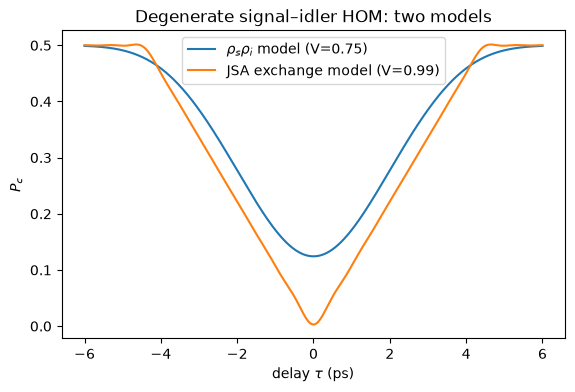

spectral purity = 0.756,  Tr[rho_s rho_i] = 0.751


In [5]:
def exchange_hom(res, taus_s, R=0.5, T=0.5, pol_overlap=1.0):
    # Same-pair HOM from the JSA exchange overlap. Requires identical signal/idler grids.
    if not np.allclose(res.SignalWavelengths, res.IdlerWavelengths):
        raise ValueError("signal and idler must share one wavelength grid")
    A = res.JSA
    f = res.c / np.asarray(res.SignalWavelengths)
    exch = A.conj() * A.T / np.sum(np.abs(A) ** 2)
    df = f[None, :] - f[:, None]  # f_signal - f_idler on the (idler, signal) grid
    X = np.array([np.real(np.sum(exch * np.exp(-1j * 2 * np.pi * df * t))) for t in taus_s])
    return R**2 + T**2 - 2 * R * T * pol_overlap * X


rho_model = hom.compute_two_mode_HOM("signal", "idler", taus_s=taus)
Pc_exch = exchange_hom(results, taus)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(taus_ps, rho_model.coincidence_probabilities,
        label=fr"$\rho_s\rho_i$ model (V={visibility(rho_model.coincidence_probabilities):.2f})")
ax.plot(taus_ps, Pc_exch, label=f"JSA exchange model (V={visibility(Pc_exch):.2f})")
ax.set(xlabel=r"delay $\tau$ (ps)", ylabel=r"$P_c$", title="Degenerate signal–idler HOM: two models")
ax.legend()
plt.show()

print(f"spectral purity = {rho_model.purity1:.3f},  Tr[rho_s rho_i] = {rho_model.overlap_at_zero_delay:.3f}")

At perfect degeneracy the exchange model gives a near-unit dip, as expected for a type-II source with a
symmetric-enough JSA. The $\rho$ model is capped by the purity. **For the signal–idler experiment, use
the exchange model.** Keep `compute_two_mode_HOM` for photons from *independent* sources (e.g. two
heralded photons). The polarization factor enters both models identically.

### Detuning by temperature

Running the crystal away from the design temperature shifts phase matching to a non-degenerate pair:
$\lambda_s \ne \lambda_i$. Below we report the detuning as the difference of the marginal-spectrum
centroids, $\Delta\lambda = \bar\lambda_s - \bar\lambda_i$, which is what a spectrometer measures.

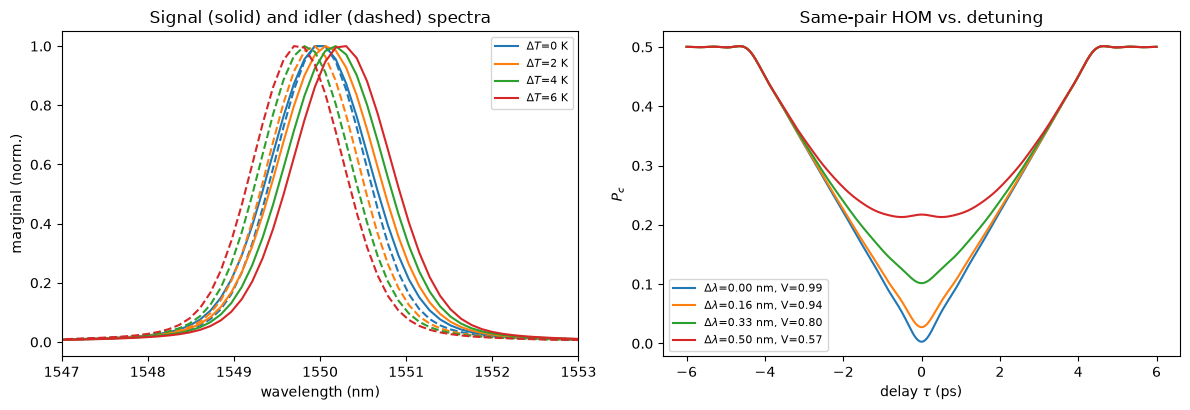

In [6]:
def centroid_detuning_nm(res):
    jsi = np.abs(res.JSA) ** 2
    wl = np.asarray(res.SignalWavelengths)
    s, i = jsi.sum(axis=0), jsi.sum(axis=1)
    return (s @ wl / s.sum() - i @ wl / i.sum()) * 1e9


fig, (ax_spec, ax_dip) = plt.subplots(1, 2, figsize=(12, 4.2))
for dT in [0, 2, 4, 6]:
    res = simulate(T_design + dT)
    jsi = np.abs(res.JSA) ** 2
    wl_nm = np.asarray(res.SignalWavelengths) * 1e9
    line, = ax_spec.plot(wl_nm, jsi.sum(axis=0) / jsi.sum(axis=0).max(), label=fr"$\Delta T$={dT} K")
    ax_spec.plot(wl_nm, jsi.sum(axis=1) / jsi.sum(axis=1).max(), ls="--", color=line.get_color())
    Pc = exchange_hom(res, taus)
    ax_dip.plot(taus_ps, Pc, color=line.get_color(),
                label=fr"$\Delta\lambda$={centroid_detuning_nm(res):.2f} nm, V={visibility(Pc):.2f}")
ax_spec.set(xlim=(1547, 1553), xlabel="wavelength (nm)", ylabel="marginal (norm.)",
            title="Signal (solid) and idler (dashed) spectra")
ax_spec.legend(fontsize=8)
ax_dip.set(xlabel=r"delay $\tau$ (ps)", ylabel=r"$P_c$", title="Same-pair HOM vs. detuning")
ax_dip.legend(fontsize=8)
plt.tight_layout()
plt.show()

Unlike a polarization offset, detuning **also changes the dip shape**. The triangular wings, whose
$\approx\pm 4.7$ ps width is set by the group-velocity mismatch over the 30 mm crystal, stay where they
are. Only the bottom of the dip fills in: the interference term picks up a beat $\propto\cos(\Delta\omega\,\tau)$
that matters near $\tau = 0$, so the dip flattens and, at larger detuning, turns into a W shape. A
polarization offset instead scales the *whole* dip, wings included. This shape difference is what lets
a fit tell the two effects apart.

## Part 4: Both effects together

The polarization and spectral factors multiply: $V = |\langle p_1|p_2\rangle|^2 \cdot V_\text{spec}(\Delta\lambda)$.
We tabulate the exchange-model dip on a grid of temperature offsets once and interpolate it in
$\Delta T$. The table is reused by the fit below.

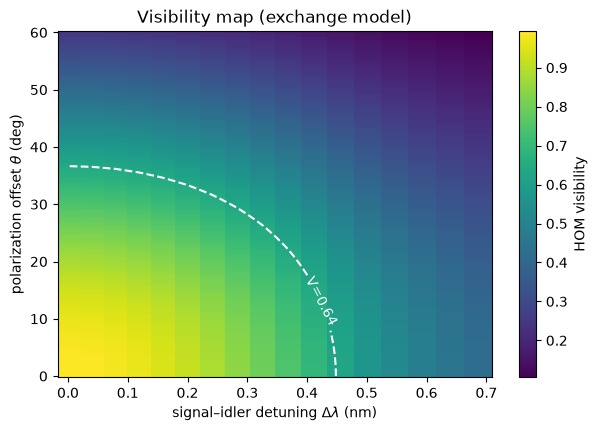

In [7]:
dTs = np.arange(0.0, 8.01, 0.5)
dip_taus_ps = np.linspace(-6, 6, 241)
X_table, detunings = [], []
for dT in dTs:
    res = simulate(T_design + dT)
    X_table.append(1 - 2 * exchange_hom(res, dip_taus_ps * 1e-12))  # interference term X(tau), R=T=1/2
    detunings.append(centroid_detuning_nm(res))
X_table, detunings = np.array(X_table), np.array(detunings)
X_interp = RegularGridInterpolator((dTs, dip_taus_ps), X_table, bounds_error=False, fill_value=0.0)

V_spec = X_table.max(axis=1)
th_grid = np.linspace(0, 60, 121)
V_map = np.cos(np.deg2rad(th_grid))[:, None] ** 2 * V_spec[None, :]

fig, ax = plt.subplots(figsize=(7, 4.5))
pcm = ax.pcolormesh(detunings, th_grid, V_map, shading="auto", cmap="viridis")
cs = ax.contour(detunings, th_grid, V_map, levels=[0.64], colors="w", linestyles="--")
ax.clabel(cs, fmt="V=0.64")
fig.colorbar(pcm, label="HOM visibility")
ax.set(xlabel=r"signal–idler detuning $\Delta\lambda$ (nm)", ylabel=r"polarization offset $\theta$ (deg)",
       title="Visibility map (exchange model)")
plt.show()

The dashed line marks every combination that gives 64%. Visibility alone can't tell which effect
dominates; the dip **shape** is needed.

### Fit template

Model the measured coincidences as

$$
N_c(\tau) = N_0\Big[\tfrac12 - \tfrac12\cos^2\theta\; X(\tau - \tau_0;\,\Delta T)\Big],
$$

with free parameters polarization offset $\theta$, detuning $\Delta T$ (equivalently
$\Delta\lambda$), delay offset $\tau_0$ and normalization $N_0$. Below we fit synthetic Poisson data
generated with a known ground truth. To use real data, replace `tau_data_ps`/`counts` with measurement data. If the source isn't this exact crystal, re-run `simulate` with the matching
parameters first.

theta =  20.5 +- 1.5 deg   (true 20.0)
dT    =  4.51 +- 0.17 K     (true 4.50)  ->  dlambda = 0.37 nm
tau0  =  0.13 +- 0.02 ps
corr(theta, dT) = -0.92


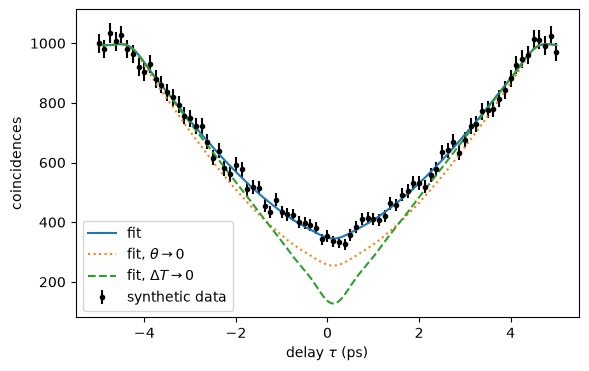

In [8]:
def dip_model(tau_ps, theta, dT, tau0_ps, N0):
    pts = np.column_stack([np.full_like(tau_ps, dT), tau_ps - tau0_ps])
    return N0 * (0.5 - 0.5 * np.cos(theta) ** 2 * X_interp(pts))


rng = np.random.default_rng(1)
tau_data_ps = np.linspace(-5, 5, 81)
truth = dict(theta=np.deg2rad(20), dT=4.5, tau0_ps=0.1, N0=2000)
counts = rng.poisson(dip_model(tau_data_ps, **truth))

p0 = [0.3, 2.0, 0.0, counts.max()]
bounds = ([0, 0, -2, 0], [np.pi / 2, dTs[-1], 2, 10 * counts.max()])
popt, pcov = curve_fit(dip_model, tau_data_ps, counts, p0=p0, bounds=bounds,
                       sigma=np.sqrt(np.maximum(counts, 1)), absolute_sigma=True)
perr = np.sqrt(np.diag(pcov))
corr = pcov[0, 1] / (perr[0] * perr[1])
dlam_fit = np.interp(popt[1], dTs, detunings)

print(f"theta = {np.rad2deg(popt[0]):5.1f} +- {np.rad2deg(perr[0]):.1f} deg   (true {np.rad2deg(truth['theta']):.1f})")
print(f"dT    = {popt[1]:5.2f} +- {perr[1]:.2f} K     (true {truth['dT']:.2f})  ->  dlambda = {dlam_fit:.2f} nm")
print(f"tau0  = {popt[2]:5.2f} +- {perr[2]:.2f} ps")
print(f"corr(theta, dT) = {corr:+.2f}")

fine = np.linspace(-5, 5, 400)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.errorbar(tau_data_ps, counts, yerr=np.sqrt(counts), fmt=".", color="k", label="synthetic data")
ax.plot(fine, dip_model(fine, *popt), label="fit")
ax.plot(fine, dip_model(fine, 0.0, popt[1], popt[2], popt[3]), ls=":", label=r"fit, $\theta\to0$")
ax.plot(fine, dip_model(fine, popt[0], 0.0, popt[2], popt[3]), ls="--", label=r"fit, $\Delta T\to0$")
ax.set(xlabel=r"delay $\tau$ (ps)", ylabel="coincidences")
ax.legend()
plt.show()

The fit recovers both parameters, but they are **strongly anti-correlated**: a bit more detuning can be
traded for a bit less polarization error. The dotted and dashed curves show how much visibility each
fix alone would restore. Some practical notes for real data:

- **Report the correlation**, not just the best-fit values. With low counts or a coarse delay scan,
  $\theta$ and $\Delta\lambda$ become nearly degenerate.
- **Break the degeneracy experimentally where possible.** Measure the signal and idler spectra directly
  (this pins $\Delta\lambda$), or put a polarizer in front of the beam splitter (this forces
  $\theta = 0$). Then fit with only one free mismatch parameter.
- **Other things that only reduce the dip depth** look exactly like a polarization error in this model:
  multi-pair emission (scales with pump power, so check a power series), accidentals and dark counts,
  spatial-mode mismatch in free-space setups, and an unbalanced beam splitter
  ($2RT/(R^2+T^2)$; 64% would need ≈ 25:75). A fitted $\theta$ is therefore an upper bound on the actual
  polarization error.
- **Sagnac sources.** With both loop directions pumped, the state is polarization-entangled, and in
  each direction the photon at a given output comes from a different crystal polarization. Polarization
  and spectrum are then coupled, and the product model above doesn't strictly apply. Pumping only one
  direction (or projecting with a polarizer) gives the clean single-source situation modeled here.

## References

1. C. K. Hong, Z. Y. Ou, L. Mandel, "Measurement of subpicosecond time intervals between two photons by
   interference," *Physical Review Letters* **59**, 2044 (1987).
2. W. P. Grice, I. A. Walmsley, "Spectral information and distinguishability in type-II
   down-conversion with a broadband pump," *Physical Review A* **56**, 1627 (1997). This paper covers
   the JSA exchange overlap and why type-II signal–idler HOM visibility is limited.
3. P. J. Mosley *et al.*, "Heralded generation of ultrafast single photons in pure quantum states,"
   *Physical Review Letters* **100**, 133601 (2008). This paper covers HOM between independent sources,
   where the visibility is set by $\mathrm{Tr}[\rho_1\rho_2]$.
4. A. M. Brańczyk, "Hong-Ou-Mandel Interference," arXiv:1711.00080 (2017). A tutorial derivation of
   the coincidence probability, including the delay dependence.
5. A. Fedrizzi, T. Herbst, A. Poppe, T. Jennewein, A. Zeilinger, "A wavelength-tunable fiber-coupled
   source of narrowband entangled photons," *Optics Express* **15**, 15377 (2007). Describes the type-II
   ppKTP Sagnac source.